# Part 1 - Basic Analysis and Statistics

The dataset is loaded from `data/health_study_dataset.csv`. Fixed random seeds make the simulations reproducible.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(42)

relative_paths = (
    Path("data/health_study_dataset.csv"),
    Path("../data/health_study_dataset.csv"),
)
dataset_path = next((path for path in relative_paths if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Could not find data/health_study_dataset.csv from the current directory."
    )

df = pd.read_csv(dataset_path)
required_columns = {
    "age", "sex", "height", "weight", "systolic_bp",
    "cholesterol", "smoker", "disease",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if df[list(required_columns)].isna().any().any():
    raise ValueError("The required dataset columns contain missing values.")

print(f"Loaded {len(df)} participants from {dataset_path}.")
display(df.head())

Loaded 800 participants from ..\data\health_study_dataset.csv.


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Descriptive Analysis

In [2]:
columns_to_analyze = ["age", "weight", "height", "systolic_bp", "cholesterol"]
summary_stats = df[columns_to_analyze].agg(["mean", "median", "min", "max"]).T
summary_stats.columns = ["Mean", "Median", "Min", "Max"]
display(summary_stats.round(2))

,Mean,Median,Min,Max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


## Visualizations

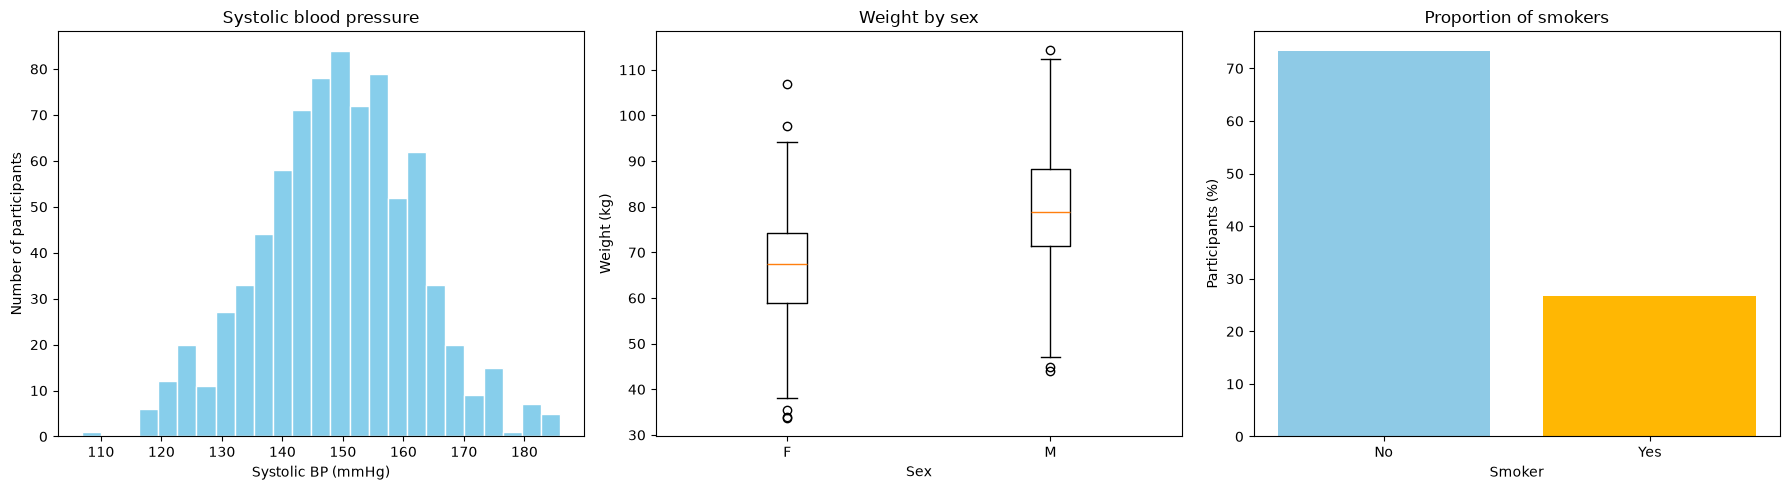

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df["systolic_bp"], bins=25, color="skyblue", edgecolor="white")
axes[0].set_title("Systolic blood pressure")
axes[0].set_xlabel("Systolic BP (mmHg)")
axes[0].set_ylabel("Number of participants")

sex_order = sorted(df["sex"].dropna().unique())
weights_by_sex = [df.loc[df["sex"] == sex, "weight"] for sex in sex_order]
axes[1].boxplot(weights_by_sex, tick_labels=sex_order)
axes[1].set_title("Weight by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Weight (kg)")

smoker_percent = df["smoker"].value_counts(normalize=True).reindex(["No", "Yes"]) * 100
axes[2].bar(smoker_percent.index, smoker_percent.values, color=["#8ecae6", "#ffb703"])
axes[2].set_title("Proportion of smokers")
axes[2].set_xlabel("Smoker")
axes[2].set_ylabel("Participants (%)")

plt.tight_layout()
plt.show()

## Simulating the Disease Rate

The disease rate in the dataset is used as the probability for each simulated outcome. A binomial simulation generates outcomes for 1,000 people, and the simulated rate is compared with the observed rate.

In [4]:
disease_values = df["disease"]
if not disease_values.isin([0, 1]).all():
    raise ValueError("The disease column must contain only 0 and 1.")

actual_disease_rate = disease_values.mean()
simulation_rng = np.random.default_rng(42)
simulated_outcomes = simulation_rng.binomial(
    n=1, p=actual_disease_rate, size=1_000
)
simulated_disease_rate = simulated_outcomes.mean()

print(f"Actual disease rate in dataset: {actual_disease_rate:.1%}")
print(f"Simulated disease rate (1,000 people): {simulated_disease_rate:.1%}")
print(
    "Difference (simulated - actual): "
    f"{simulated_disease_rate - actual_disease_rate:+.1%}"
)

Actual disease rate in dataset: 5.9%
Simulated disease rate (1,000 people): 5.4%
Difference (simulated - actual): -0.5%


## Confidence Intervals for Mean Systolic Blood Pressure

The normal-approximation and bootstrap percentile 95% confidence intervals are both shown below. Their bounds are very close.

In [5]:
systolic_bp = df["systolic_bp"].to_numpy()
sample_mean = systolic_bp.mean()
standard_error = systolic_bp.std(ddof=1) / np.sqrt(len(systolic_bp))
normal_ci = (
    sample_mean - 1.96 * standard_error,
    sample_mean + 1.96 * standard_error,
)

ci_rng = np.random.default_rng(42)
n_bootstrap = 10_000
bootstrap_samples = ci_rng.choice(
    systolic_bp, size=(n_bootstrap, len(systolic_bp)), replace=True
)
bootstrap_means = bootstrap_samples.mean(axis=1)
bootstrap_ci = tuple(np.quantile(bootstrap_means, [0.025, 0.975]))

print(f"Sample mean systolic BP: {sample_mean:.2f} mmHg")
print(
    "95% normal-approximation CI: "
    f"({normal_ci[0]:.2f}, {normal_ci[1]:.2f}) mmHg"
)
print(
    "95% bootstrap percentile CI: "
    f"({bootstrap_ci[0]:.2f}, {bootstrap_ci[1]:.2f}) mmHg"
)

Sample mean systolic BP: 149.18 mmHg
95% normal-approximation CI: (148.29, 150.07) mmHg
95% bootstrap percentile CI: (148.31, 150.05) mmHg


## Hypothesis Test: Do Smokers Have Higher Systolic Blood Pressure?

- **Null hypothesis (H0):** smokers do not have a higher mean systolic blood pressure than non-smokers.
- **Alternative hypothesis (H1):** smokers have a higher mean systolic blood pressure than non-smokers.

A one-sided permutation test compares the group means. The significance level is 0.05. This test evaluates evidence for a difference in this dataset; it does not show that smoking causes a difference.

In [6]:
smoker_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].to_numpy()
non_smoker_bp = df.loc[df["smoker"] == "No", "systolic_bp"].to_numpy()
if len(smoker_bp) == 0 or len(non_smoker_bp) == 0:
    raise ValueError("Both smoker groups must contain observations.")

observed_difference = smoker_bp.mean() - non_smoker_bp.mean()
pooled_bp = np.concatenate([smoker_bp, non_smoker_bp])
n_smokers = len(smoker_bp)
n_permutations = 10_000
permutation_rng = np.random.default_rng(42)
permuted_differences = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled_bp = permutation_rng.permutation(pooled_bp)
    permuted_differences[i] = (
        shuffled_bp[:n_smokers].mean() - shuffled_bp[n_smokers:].mean()
    )

p_value = (
    np.count_nonzero(permuted_differences >= observed_difference) + 1
) / (n_permutations + 1)
alpha = 0.05

print(f"Smokers' mean systolic BP: {smoker_bp.mean():.2f} mmHg")
print(f"Non-smokers' mean systolic BP: {non_smoker_bp.mean():.2f} mmHg")
print(f"Observed difference (smokers - non-smokers): {observed_difference:.2f} mmHg")
print(f"One-sided permutation-test p-value: {p_value:.4f}")
print(f"Significance level: {alpha:.2f}")

Smokers' mean systolic BP: 149.52 mmHg
Non-smokers' mean systolic BP: 149.05 mmHg
Observed difference (smokers - non-smokers): 0.47 mmHg
One-sided permutation-test p-value: 0.3246
Significance level: 0.05


### Interpretation

In this dataset, smokers' mean systolic blood pressure is **0.47 mmHg higher** than non-smokers'. The permutation test gives **p = 0.3246**, which is greater than 0.05. We therefore fail to reject the null hypothesis: the result does not provide sufficient statistical evidence that smokers have higher mean blood pressure in this dataset. This does not prove that the groups are equal.

## VG Extension: Simulating Test Power

Participants are resampled within each smoking group, and each simulated difference is compared with the 5% permutation-test critical value. The rejection rate estimates the test's power for the observed effect.

In [7]:
n_power_simulations = 2_000
critical_difference = np.quantile(permuted_differences, 1 - alpha)
power_rng = np.random.default_rng(43)

simulated_smoker_means = power_rng.choice(
    smoker_bp, size=(n_power_simulations, len(smoker_bp)), replace=True
).mean(axis=1)
simulated_non_smoker_means = power_rng.choice(
    non_smoker_bp, size=(n_power_simulations, len(non_smoker_bp)), replace=True
).mean(axis=1)
simulated_differences = simulated_smoker_means - simulated_non_smoker_means
rejections = simulated_differences >= critical_difference
estimated_power = rejections.mean()
monte_carlo_se = np.sqrt(
    estimated_power * (1 - estimated_power) / n_power_simulations
)

print(f"One-sided 5% critical difference: {critical_difference:.2f} mmHg")
print(
    f"Estimated power at the observed group difference: "
    f"{estimated_power:.1%} ({rejections.sum()}/{n_power_simulations} simulations)"
)
print(f"Approximate Monte Carlo standard error: {monte_carlo_se:.1%}")

One-sided 5% critical difference: 1.67 mmHg
Estimated power at the observed group difference: 12.2% (244/2000 simulations)
Approximate Monte Carlo standard error: 0.7%


## Method Choices and References

The normal approximation is a simple reference interval for the mean; the bootstrap interval checks uncertainty by repeatedly resampling observations. The permutation test compares group means without assuming normally distributed blood pressure. Disease simulation and resampling use `numpy.random.default_rng` with fixed seeds for reproducibility.

- NumPy, *Random sampling (`Generator`)*: https://numpy.org/doc/stable/reference/random/generator.html

**Reproducibility:** restart the kernel and run all cells from top to bottom. The notebook expects `data/health_study_dataset.csv` in the project's `data` folder.